# Task 18: Manual Violin Plots

## Objective
To visualize the distribution of numerical features across target classes
by manually implementing Kernel Density Estimation (KDE) and constructing
violin plots without using built-in violin plot functions.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../../datasets/heart.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print("\nColumns:", list(df.columns))

Dataset Shape: (1025, 14)
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   52    1   0       125   212    0        1      168      0      1.0      2   
1   53    1   0       140   203    1        0      155      1      3.1      0   
2   70    1   0       145   174    0        1      125      1      2.6      0   
3   61    1   0       148   203    0        1      161      0      0.0      2   
4   62    0   0       138   294    1        1      106      0      1.9      1   

   ca  thal  target  
0   2     3       0  
1   0     3       0  
2   0     3       0  
3   1     3       0  
4   3     2       0  

Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [4]:
required_columns = ["age", "chol", "thalach", "target"]

for col in required_columns:
    if col not in df.columns:
        raise ValueError(f"Required column '{col}' not found.")

plot_df = df[required_columns].copy()

for col in required_columns:
    plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

plot_df = plot_df.dropna().reset_index(drop=True)

print("Rows available:", len(plot_df))
print("Target classes:", sorted(plot_df["target"].unique()))

Rows available: 1025
Target classes: [np.int64(0), np.int64(1)]


## Manual Kernel Density Estimation (KDE)

KDE estimates the probability density of numerical data using a smooth
kernel function. Here, the Gaussian kernel and bandwidth are implemented
manually using Python loops and mathematical operations.

In [5]:
def manual_kde(data, points, bandwidth):
    data = list(data)
    densities = []

    if len(data) == 0:
        return [0.0] * len(points)

    if bandwidth <= 0:
        raise ValueError("Bandwidth must be greater than zero.")

    for point in points:
        total = 0

        for value in data:
            z = (point - value) / bandwidth

            kernel = (
                1 / (2 * np.pi) ** 0.5
            ) * np.exp(-0.5 * z ** 2)

            total += kernel

        density = total / (len(data) * bandwidth)
        densities.append(density)

    return densities

In [6]:
def manual_violin_plot(ax, data, position, color, label):
    data = list(data)

    if len(data) < 2:
        print(f"Not enough observations for {label}")
        return

    minimum = min(data)
    maximum = max(data)

    if minimum == maximum:
        print(f"No variation in data for {label}")
        return

    data_range = maximum - minimum

    # Create evaluation points for KDE
    padding = data_range * 0.1
    y_points = np.linspace(
        minimum - padding,
        maximum + padding,
        100
    )

    # Silverman's rule for bandwidth
    mean_value = sum(data) / len(data)
    variance = sum((value - mean_value) ** 2 for value in data) / (
        len(data) - 1
    )
    standard_deviation = variance ** 0.5

    bandwidth = 1.06 * standard_deviation * (
        len(data) ** (-1 / 5)
    )

    if bandwidth <= 0:
        bandwidth = data_range / 20

    density = manual_kde(data, y_points, bandwidth)

    max_density = max(density)

    if max_density == 0:
        return

    # Scale density to form the violin shape
    half_width = [
        (value / max_density) * 0.35
        for value in density
    ]

    left = [position - width for width in half_width]
    right = [position + width for width in half_width]

    ax.fill(
        left + right[::-1],
        list(y_points) + list(y_points[::-1]),
        facecolor=color,
        alpha=0.55,
        edgecolor="black",
        linewidth=1
    )

    # Add median line
    sorted_data = sorted(data)
    count = len(sorted_data)

    if count % 2 == 1:
        median = sorted_data[count // 2]
    else:
        median = (
            sorted_data[count // 2 - 1]
            + sorted_data[count // 2]
        ) / 2

    ax.plot(
        [position - 0.15, position + 0.15],
        [median, median],
        color="black",
        linewidth=2
    )

    ax.text(
        position,
        maximum + padding,
        label,
        ha="center",
        va="bottom",
        fontsize=9
    )

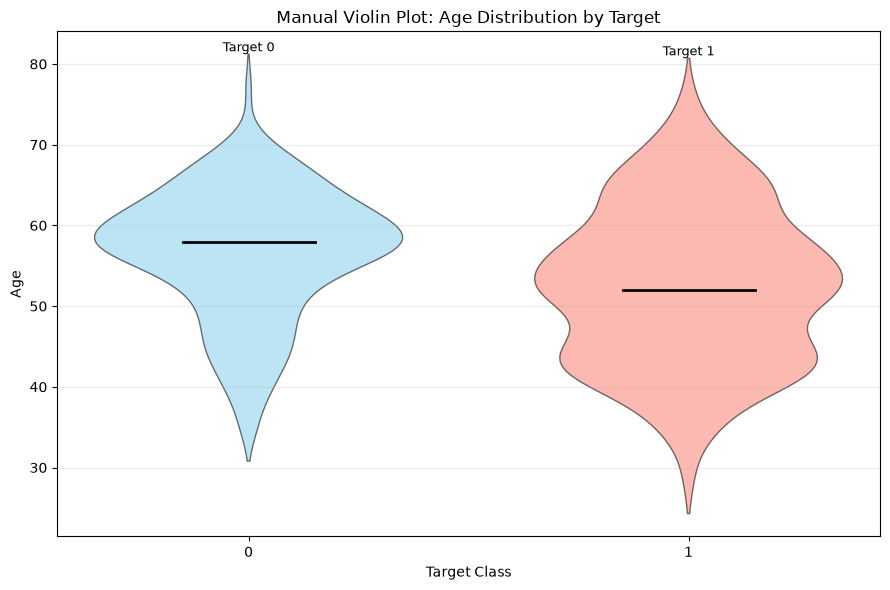

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

target_classes = sorted(plot_df["target"].unique())
positions = list(range(len(target_classes)))

colors = ["skyblue", "salmon", "lightgreen", "plum"]

for i, target_value in enumerate(target_classes):
    values = plot_df.loc[
        plot_df["target"] == target_value, "age"
    ].tolist()

    manual_violin_plot(
        ax,
        values,
        positions[i],
        colors[i % len(colors)],
        f"Target {target_value}"
    )

ax.set_xticks(positions)
ax.set_xticklabels([str(value) for value in target_classes])
ax.set_xlabel("Target Class")
ax.set_ylabel("Age")
ax.set_title("Manual Violin Plot: Age Distribution by Target")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

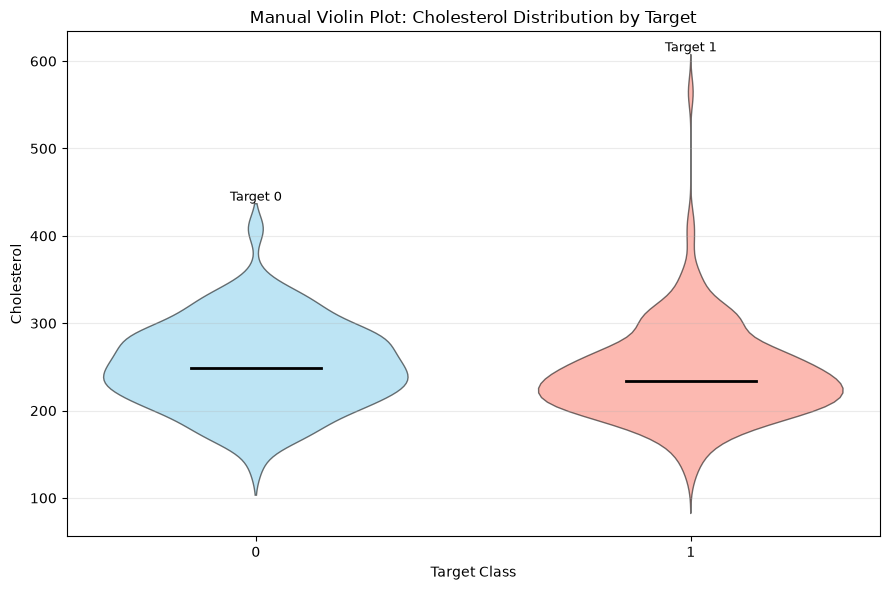

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))

for i, target_value in enumerate(target_classes):
    values = plot_df.loc[
        plot_df["target"] == target_value, "chol"
    ].tolist()

    manual_violin_plot(
        ax,
        values,
        positions[i],
        colors[i % len(colors)],
        f"Target {target_value}"
    )

ax.set_xticks(positions)
ax.set_xticklabels([str(value) for value in target_classes])
ax.set_xlabel("Target Class")
ax.set_ylabel("Cholesterol")
ax.set_title("Manual Violin Plot: Cholesterol Distribution by Target")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

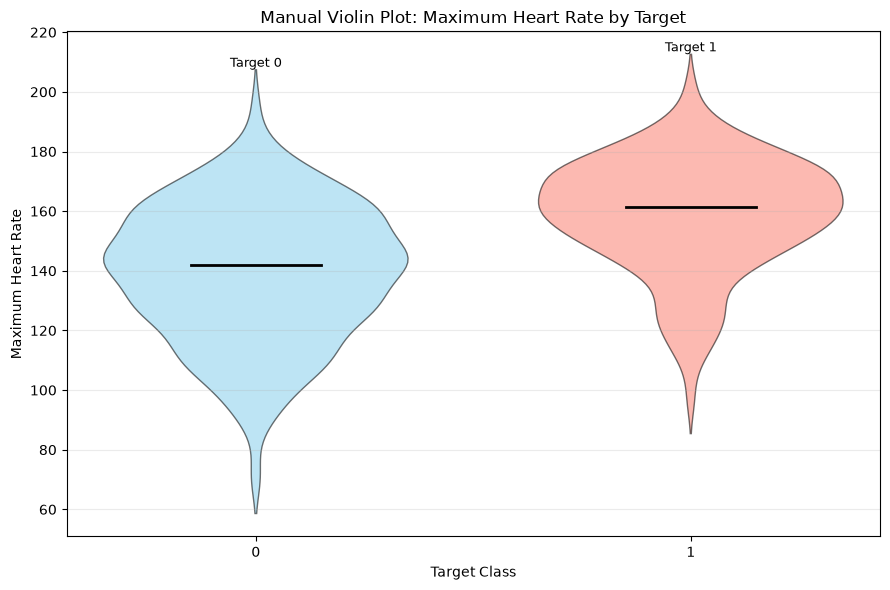

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))

for i, target_value in enumerate(target_classes):
    values = plot_df.loc[
        plot_df["target"] == target_value, "thalach"
    ].tolist()

    manual_violin_plot(
        ax,
        values,
        positions[i],
        colors[i % len(colors)],
        f"Target {target_value}"
    )

ax.set_xticks(positions)
ax.set_xticklabels([str(value) for value in target_classes])
ax.set_xlabel("Target Class")
ax.set_ylabel("Maximum Heart Rate")
ax.set_title("Manual Violin Plot: Maximum Heart Rate by Target")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

## Conclusion

In this task, violin plots were constructed by manually implementing
Gaussian Kernel Density Estimation (KDE). The estimated densities were
used to create violin shapes, and median lines were added to summarize
the distributions. Age, cholesterol, and maximum heart rate were compared
across target classes. These plots help visualize differences in data
distributions but do not establish causation or provide a medical diagnosis.